In [8]:
import os
import json
import argparse
import numpy as np
import tkinter as tk
from tkinter import Button, Tk, Frame, font
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg


def read_file(file_path):
    data = []
    with open(file_path, 'r') as file:
        next(file) # ignore the first line
        for line in file:
            parts = line.split()
            row = list(map(float, parts))
            data.append(row)
    return data


def plot_data_HDQ(ax, base_path='./save/imagenet/resnet18', lower=1, upper=100):
    HDQ_file = os.path.join(base_path,"HDQ.txt")
    data = read_file(HDQ_file)
    # plot baseline for HDQ
    QF_ls = [int(row[0]) for row in data]
    HDQ_y = [row[1] for row in data]
    HDQ_x = [row[2] for row in data]
    
    sorted_lists = [(qf, y, x) for qf, y, x in sorted(zip(QF_ls, HDQ_y, HDQ_x)) if lower <= qf <= upper]

    QF_ls, HDQ_y, HDQ_x = map(list, zip(*sorted_lists))
    
    ax.plot(HDQ_x, HDQ_y, marker="x", color='k')
    # for i, (x, y) in enumerate(zip(HDQ_x, HDQ_y)):
    #     ax.annotate(str(QF_ls[i]), (x, y), textcoords="offset points", xytext=(5,-7), ha='center', fontsize=8)
        

colors_list = ['red', 'green', 'blue', 'cyan', 'magenta', 'yellow', 'black', 'orange', 'purple', 'brown']
marker_list = ['o','^','.','v','>','v','|','_',',','x']


# base_path = './save/CUB200/resnet18'
base_path = './save/imagenet/resnet18'

# Plot accuracy

In [9]:
color_marker_index = 0
plot_references = {}


def get_greedy_BPP(x_values, y_values):
    """Select points based on greedy algorithm focusing on better y values with less or equal x values."""
    # Sort data by y_values while maintaining correspondence with x_values and their original indices
    sorted_pairs = sorted(zip(y_values, x_values, range(len(y_values))), key=lambda x: x[0], reverse=True)
    sorted_y_values, sorted_x_values, sorted_indices = zip(*sorted_pairs)

    # Initialize with the best found values (highest y)
    best_y = sorted_y_values[0]
    best_x = sorted_x_values[0]
    # print(f"Best accuracy: {best_y:.8f} at epoch: {sorted_indices[0]+1} with BPP: {best_x:.8f}")
    
    new_y, new_x, new_indices = [], [], []
    for idx, (x_val, y_val) in enumerate(zip(sorted_x_values, sorted_y_values)):
        # Update best seen values and collect if current point is better or equal
        if x_val <= best_x and y_val <= best_y:
            best_x, best_y = x_val, y_val
            new_x.append(x_val)
            new_y.append(y_val)
            new_indices.append(sorted_indices[idx])

    return new_x, new_y, new_indices


def toggle_plot(fig, ax, canvas, file_path, button, marker='o', label='Data', greedy=True):
    global color_marker_index, plot_references
    
    # JPEG baseline
    plot_data_HDQ(ax, base_path, lower=1, upper=100)
    
    # Toggle off if already plotted
    if file_path in plot_references:
        for item in plot_references[file_path]:
            item.remove()
        del plot_references[file_path]
        button.config(relief="raised")
        ax.legend(loc="lower right")
        canvas.draw()
        return

    # Plot the data
    data = read_file(file_path)
    y_values = [row[2] for row in data]
    x_values = [row[6] for row in data]
    current_color = colors_list[color_marker_index % len(colors_list)]
    current_marker = marker_list[color_marker_index % len(marker_list)]
    color_marker_index += 1

    plot_items = []
    
    if greedy:
        new_x_values, new_y_values, new_indices = get_greedy_BPP(x_values, y_values)
        line1 = ax.plot(x_values, y_values, marker=current_marker, color=current_color, alpha=0.2, linestyle="")
        line2 = ax.plot(new_x_values, new_y_values, marker=current_marker, label=label, color=current_color, alpha=1)
        plot_items.extend(line1)
        plot_items.extend(line2)
        # for i, (x, y) in enumerate(zip(new_x_values, new_y_values)):
        #     annotation = ax.annotate(str(new_indices[i]+1), (x, y), textcoords="offset points", xytext=(0,10), ha='center')
        #     plot_items.append(annotation)
    else:
        line = ax.plot(x_values, y_values, marker=current_marker, label=label, color=current_color, alpha=0.9)
        plot_items.append(line)

    plot_references[file_path] = plot_items
    button.config(relief="sunken")  # Change the button appearance to indicate it's active
    ax.legend(loc="lower right")
    canvas.draw()


def create_gallery_1(base_path):
    root = Tk()
    root.title("Data Gallery")
    # root.attributes('-fullscreen', True)
    root.state('zoomed')
    
    fig = Figure(figsize=(10, 6))
    ax = fig.add_subplot(111)

    canvas = FigureCanvasTkAgg(fig, master=root)
    canvas_widget = canvas.get_tk_widget()
    canvas_widget.pack(side=tk.TOP, fill=tk.BOTH, expand=True)

    button_frame = Frame(root)
    button_frame.pack(side=tk.BOTTOM, fill=tk.X)

    # directories = [d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))]
    directories = [d for d in os.listdir(base_path) if (os.path.isdir(os.path.join(base_path, d))) ]
    print(directories)
    row, col = 0, 0
    custom_font = font.Font(family="Helvetica", size=8, weight="bold")
    for dir_name in directories:
        file_path = os.path.join(base_path, dir_name, "trial_1", "logs.txt")
        button = Button(button_frame, text=dir_name, relief="raised", font=custom_font)
        button.grid(row=row, column=col, sticky="ew")
        button.config(command=lambda b=button, f=file_path, l=dir_name: toggle_plot(fig, ax, canvas, f, b, label=l))
        col += 1
        if col % 8 == 0:
            row += 1
            col = 0

    root.mainloop()


create_gallery_1(base_path)

['JPEG_lr_0.0001_alpha_100.0_weight_0.001_0.001_QF_10', 'JPEG_lr_0.0001_alpha_100.0_weight_0.001_0.001_QF_100', 'JPEG_lr_0.0001_alpha_100.0_weight_0.001_0.001_QF_20', 'JPEG_lr_0.0001_alpha_100.0_weight_0.001_0.001_QF_30', 'JPEG_lr_0.0001_alpha_100.0_weight_0.001_0.001_QF_40', 'JPEG_lr_0.0001_alpha_100.0_weight_0.001_0.001_QF_50', 'JPEG_lr_0.0001_alpha_100.0_weight_0.001_0.001_QF_60', 'JPEG_lr_0.0001_alpha_100.0_weight_0.001_0.001_QF_70', 'JPEG_lr_0.0001_alpha_100.0_weight_0.001_0.001_QF_80', 'JPEG_lr_0.0001_alpha_100.0_weight_0.001_0.001_QF_90', 'JPEG_lr_0.0001_alpha_100.0_weight_0.01_0.01_QF_10', 'JPEG_lr_0.0001_alpha_100.0_weight_0.01_0.01_QF_100', 'JPEG_lr_0.0001_alpha_100.0_weight_0.01_0.01_QF_20', 'JPEG_lr_0.0001_alpha_100.0_weight_0.01_0.01_QF_30', 'JPEG_lr_0.0001_alpha_100.0_weight_0.01_0.01_QF_40', 'JPEG_lr_0.0001_alpha_100.0_weight_0.01_0.01_QF_50', 'JPEG_lr_0.0001_alpha_100.0_weight_0.01_0.01_QF_60', 'JPEG_lr_0.0001_alpha_100.0_weight_0.01_0.01_QF_70', 'JPEG_lr_0.0001_alpha_1

# Plot Matrix

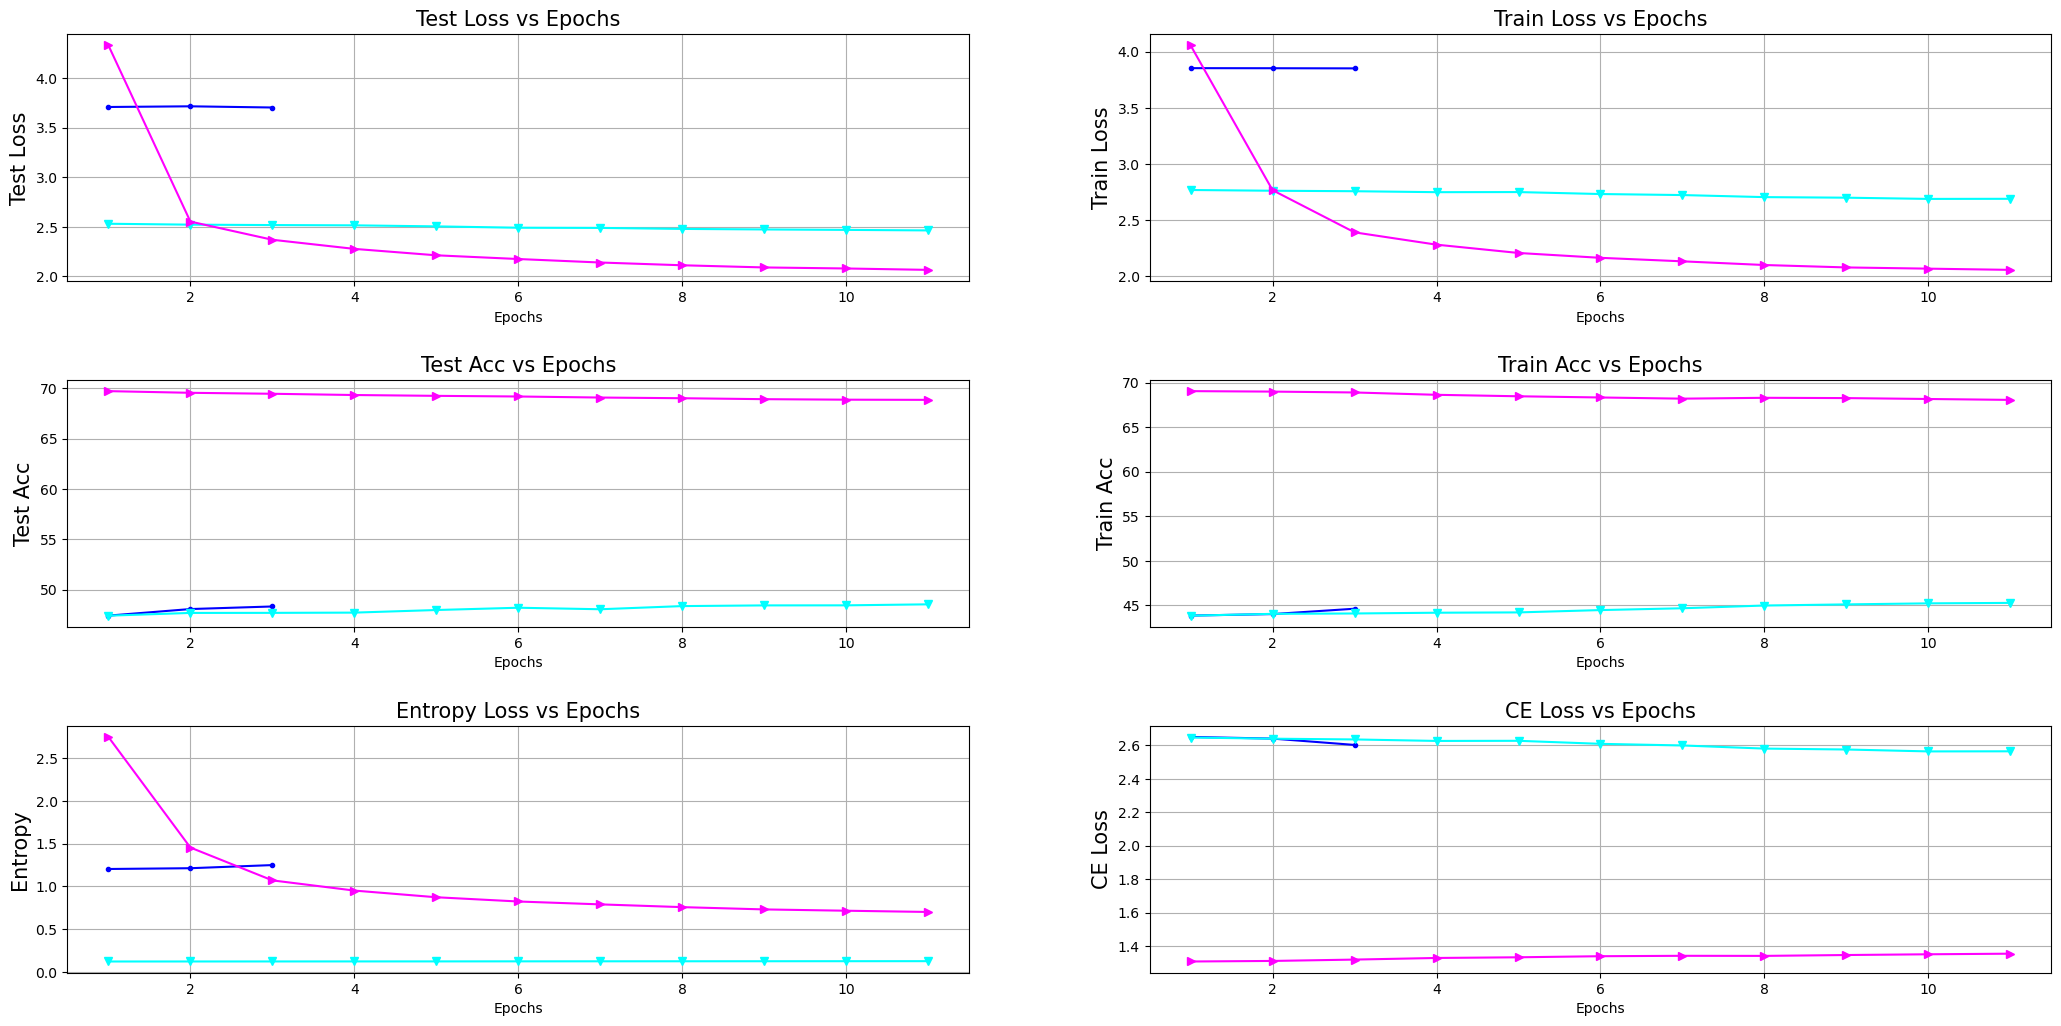

In [6]:
def plot_data_acc_loss(axs, file_path, button, label):
    global color_marker_index, plot_references

    # Toggle off if already plotted
    if file_path in plot_references:
        for item in plot_references[file_path]:
            item.remove()
        del plot_references[file_path]
        button.config(relief="raised")
        for ax in axs:
            ax.legend(loc="lower right")
            ax.figure.canvas.draw()
        return

    current_color = colors_list[color_marker_index % len(colors_list)]
    current_marker = marker_list[color_marker_index % len(marker_list)]
    color_marker_index += 1

    file_path_opt = os.path.join(file_path, "opt.json")
    with open(file_path_opt, 'r') as f:
        opt = json.load(f)
        opt = argparse.Namespace(**opt)

    weight = opt.weight_lum
    file_path_log = os.path.join(file_path, "logs.txt")
    data = read_file(file_path_log)

    test_acc = [row[2] for row in data]
    train_acc = [row[3] for row in data]
    test_loss = [row[4] for row in data]
    train_loss = [row[5] for row in data]
    entropy = [weight * (row[11] + row[12] + row[13] + row[14]) for row in data]
    CEloss = [row[5] - weight * (row[11] + row[12] + row[13] + row[14]) for row in data]
    x_epoch = range(1, len(test_loss) + 1)

    plot_items = []
    
    # Plotting on each subplot
    plot_items.append(axs[0].plot(x_epoch, test_loss, marker=current_marker, color=current_color)[0])
    plot_items.append(axs[1].plot(x_epoch, train_loss, marker=current_marker, color=current_color)[0])
    plot_items.append(axs[2].plot(x_epoch, test_acc, marker=current_marker, color=current_color)[0])
    plot_items.append(axs[3].plot(x_epoch, train_acc, marker=current_marker, color=current_color)[0])
    plot_items.append(axs[4].plot(x_epoch, entropy, marker=current_marker, color=current_color)[0])
    plot_items.append(axs[5].plot(x_epoch, CEloss, marker=current_marker, color=current_color)[0])

    titles = ['Test Loss vs Epochs', 'Train Loss vs Epochs', 'Test Acc vs Epochs', 'Train Acc vs Epochs', 'Entropy Loss vs Epochs', 'CE Loss vs Epochs']
    y_labels = ['Test Loss', 'Train Loss', 'Test Acc', 'Train Acc', 'Entropy', 'CE Loss']

    for idx, (title, y_label) in enumerate(zip(titles, y_labels)):
        axs[idx].set_xlabel('Epochs')
        axs[idx].set_ylabel(y_label, fontsize=15)
        axs[idx].grid(True)
        axs[idx].set_title(title, fontsize=15)
        # axs[idx].legend(loc="lower right")

    plot_references[file_path] = plot_items
    button.config(relief="sunken")  # Change the button appearance to indicate it's active
    for ax in axs:
        ax.figure.canvas.draw()


def create_gallery_2(base_path):
    root = Tk()
    root.title("Data Gallery")
    root.state('zoomed')

    fig, axs = plt.subplots(3, 2, figsize=(15, 10))
    plt.subplots_adjust(hspace=0.4)
    axs = axs.flatten()  # Flatten the array to make indexing easier

    canvas = FigureCanvasTkAgg(fig, master=root)
    canvas_widget = canvas.get_tk_widget()
    canvas_widget.pack(side='top', fill='both', expand=True)

    button_frame = Frame(root)
    button_frame.pack(side='bottom', fill='x')

    directories = [d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))]
    row, col = 0, 0
    custom_font = font.Font(family="Helvetica", size=8, weight="bold")
    for dir_name in directories:
        file_path = os.path.join(base_path, dir_name, "trial_1")
        button = Button(button_frame, text=dir_name, relief="raised", font=custom_font)
        button.config(command=lambda b=button, f=file_path, a=axs: plot_data_acc_loss(a, f, b, dir_name))
        button.grid(row=row, column=col, sticky="ew")
        col += 1
        if col % 8 == 0:
            row += 1
            col = 0

    root.mainloop()


create_gallery_2(base_path)

# Plot Q table

len of q_tables 11
len of q_tables 3
len of q_tables 11


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


len of q_tables 11


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


len of q_tables 11


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


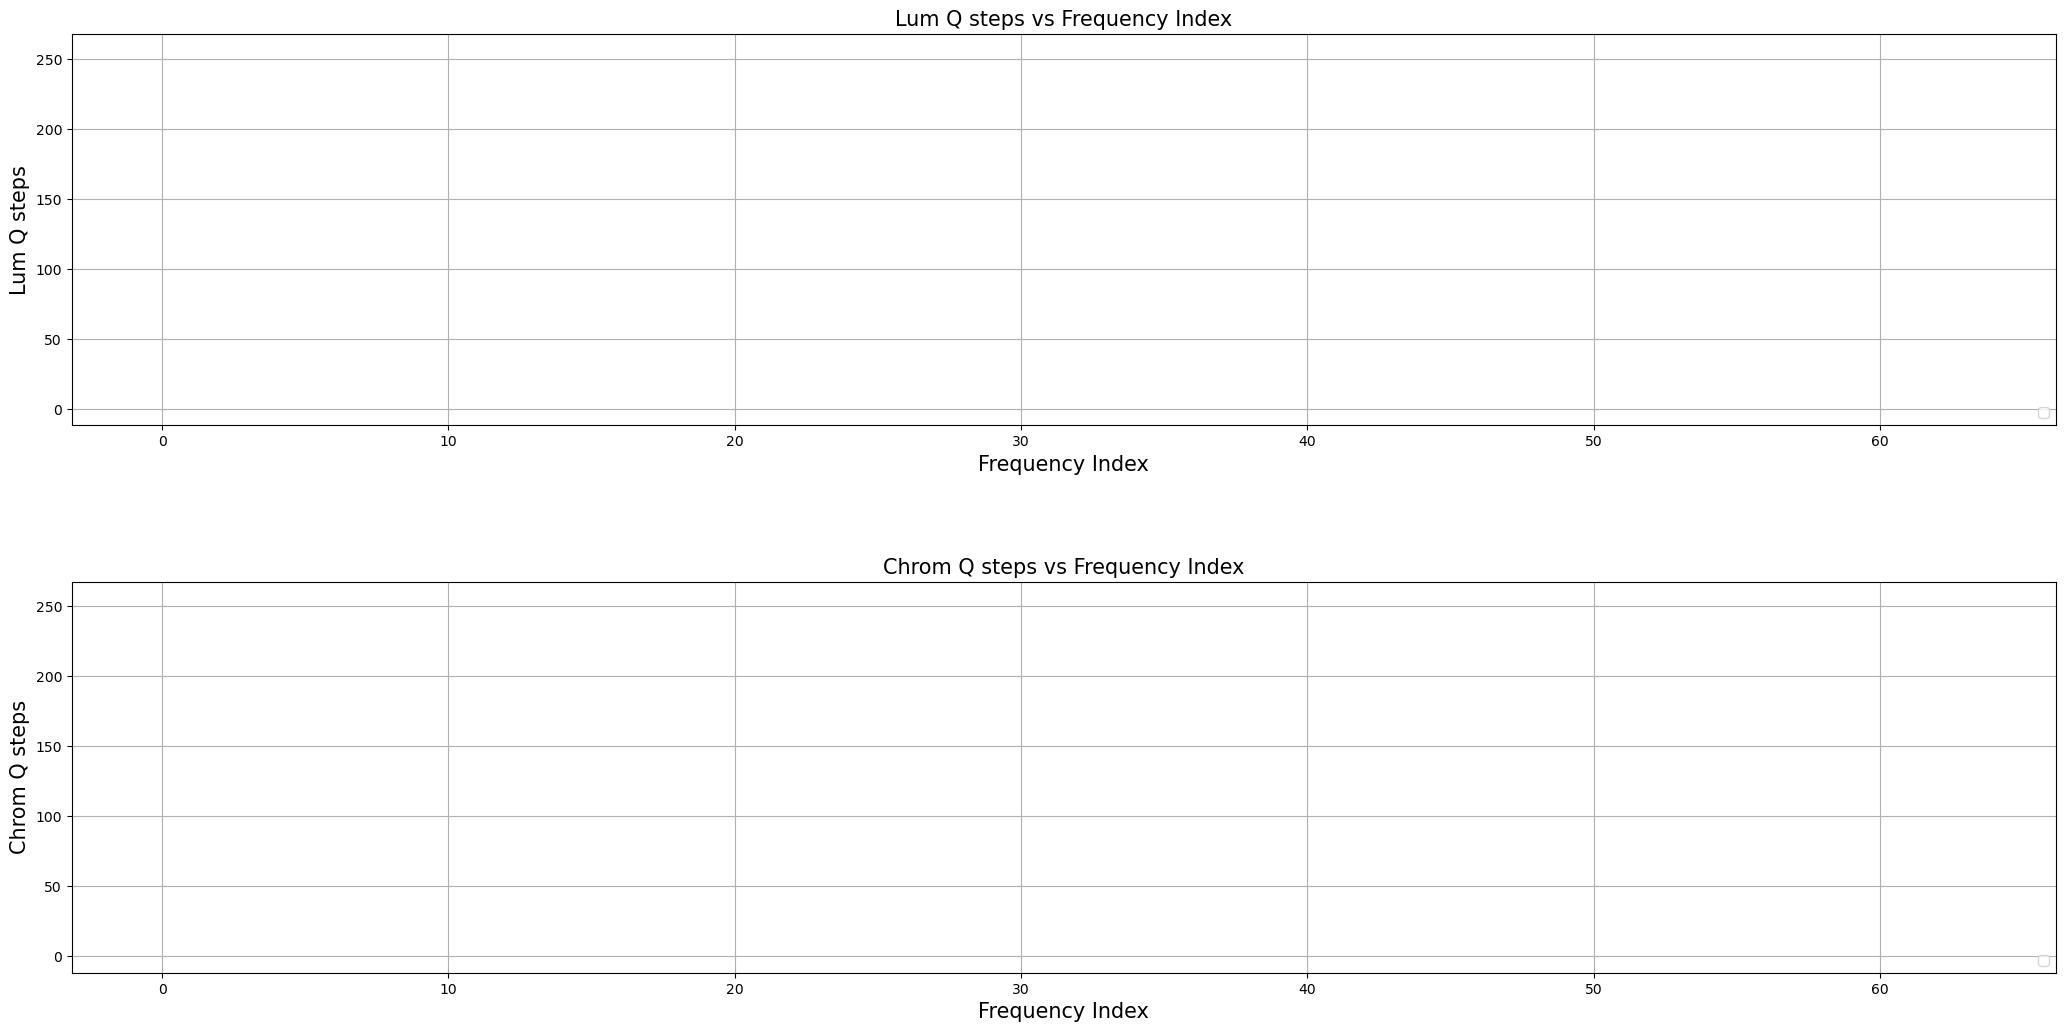

In [7]:
color_marker_index = 0
plot_references = {}


def zigzag(matrix):
    zigzag = np.array([[0, 1, 5, 6, 14, 15, 27, 28],
                       [2, 4, 7, 13, 16, 26, 29, 42],
                       [3, 8, 12, 17, 25, 30, 41, 43],
                       [9, 11, 18, 24, 31, 40, 44, 53],
                       [10, 19, 23, 32, 39, 45, 52, 54],
                       [20, 22, 33, 38, 46, 51, 55, 60],
                       [21, 34, 37, 47, 50, 56, 59, 61],
                       [35, 36, 48, 49, 57, 58, 62, 63]])
    matrix_size = np.shape(matrix)
    vector_size = np.shape(zigzag)
    if matrix_size != vector_size:
        raise ValueError("The matrix size does not match the vector size.")
    vector = np.zeros(matrix_size[0] * matrix_size[1])
    for i in range(matrix_size[0]):
        for j in range(matrix_size[1]):
            index = zigzag[i, j]
            vector[index] = matrix[i, j]
    return vector


def plot_q_table(ax1, ax2, file_path, button, label, epoch_choose=-1):
    global color_marker_index, plot_references

    # Toggle off if already plotted
    if file_path in plot_references:
        for item in plot_references[file_path]:
            item.remove()
        del plot_references[file_path]
        button.config(relief="raised")
        ax1.legend(loc="lower right")
        ax2.legend(loc="lower right")
        ax1.figure.canvas.draw()
        ax2.figure.canvas.draw()
        return

    current_color = colors_list[color_marker_index % len(colors_list)]
    current_marker = marker_list[color_marker_index % len(marker_list)]
    color_marker_index += 1

    with open(os.path.join(file_path, "lum_q_table.txt"), "r") as lum_file:
        lum_lines = lum_file.read()
    lum_tables = lum_lines.split("\n\n")[:-1]

    with open(os.path.join(file_path, "chrom_q_table.txt"), "r") as chrom_file:
        chrom_lines = chrom_file.read()
    chrom_tables = chrom_lines.split("\n\n")[:-1]

    if len(lum_tables) == 102:
        lum_tables = lum_tables[1:]
        chrom_tables = chrom_tables[1:]
    print("len of q_tables", len(lum_tables))

    plot_items = []

    # plot lum q_table
    for epoch, (lum_table, chrom_table) in enumerate(zip(lum_tables, chrom_tables)):
        if epoch_choose >= 0:
            # only print the lun/chrom qtable for this epoch
            if epoch != epoch_choose:
                continue
        elif epoch % 1 != 0:
            continue

        Lum_matrix = np.array([list(map(float, row.split(","))) for row in lum_table.split("\n")])
        Lum_matrix = zigzag(Lum_matrix).flatten()

        chrom_matrix = np.array([list(map(float, row.split(","))) for row in chrom_table.split("\n")])
        chrom_matrix = zigzag(chrom_matrix).flatten()

        if epoch == 0:
            plot_items.append(ax1.plot(Lum_matrix, marker=current_marker, label=" epoch {}".format(epoch), alpha=1, color="k")[0])
            plot_items.append(ax2.plot(chrom_matrix, marker=current_marker, label=" epoch {}".format(epoch), alpha=1, color="k")[0])
        else:
            plot_items.append(ax1.plot(Lum_matrix, marker=current_marker, label=" epoch {}".format(epoch), alpha=0.5)[0])
            plot_items.append(ax2.plot(chrom_matrix, marker=current_marker, label=" epoch {}".format(epoch), alpha=0.5)[0])

    ax1.set_xlabel('Frequency Index', fontsize=15)
    ax1.set_ylabel('Lum Q steps', fontsize=15)
    ax1.set_title('Lum Q steps vs Frequency Index', fontsize=15)
    ax1.grid(True)

    ax2.set_xlabel('Frequency Index', fontsize=15)
    ax2.set_ylabel('Chrom Q steps', fontsize=15)
    ax2.set_title('Chrom Q steps vs Frequency Index', fontsize=15)
    ax2.grid(True)

    plot_references[file_path] = plot_items
    button.config(relief="sunken")  # Change the button appearance to indicate it's active
    plt.legend(bbox_to_anchor=(1.02, 1.5), loc=2, borderaxespad=0)
    ax1.figure.canvas.draw()
    ax2.figure.canvas.draw()


def create_gallery_3(base_path):
    root = Tk()
    root.title("Data Gallery")
    root.state('zoomed')

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6))
    plt.subplots_adjust(hspace=0.4)
    
    canvas = FigureCanvasTkAgg(fig, master=root)
    canvas_widget = canvas.get_tk_widget()
    canvas_widget.pack(side='top', fill='both', expand=True)

    button_frame = Frame(root)
    button_frame.pack(side='bottom', fill='x')

    directories = [d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))]
    row, col = 0, 0
    custom_font = font.Font(family="Helvetica", size=8, weight="bold")
    for dir_name in directories:
        file_path = os.path.join(base_path, dir_name, "trial_1", "Q_tables")
        button = Button(button_frame, text=dir_name, relief="raised", font=custom_font)
        button.config(command=lambda b=button, f=file_path, a1=ax1, a2=ax2: plot_q_table(a1, a2, f, b, dir_name))
        button.grid(row=row, column=col, sticky="ew")
        col += 1
        if col % 8 == 0:
            row += 1
            col = 0

    root.mainloop()


create_gallery_3(base_path)